# Predictive Customer Churn Model for ConnectTel

## Machine Learning Project

### Objective

Build an end-to-end machine learning system that predicts customer churn and helps ConnectTel identify customer segments that may require proactive retention actions.

### Project Pipeline

```text
Data Collection
      ↓
Data Cleaning
      ↓
Exploratory Data Analysis
      ↓
Feature Engineering
      ↓
Train / Test Split
      ↓
Preprocessing
      ↓
Model Training
      ↓
5-Fold Cross-Validation
      ↓
Hyperparameter Tuning
      ↓
Model Evaluation
      ↓
SHAP Explainability
      ↓
Business Insights & Recommendations
```

### Notebook Contents

1. Problem Statement
2. Dataset Overview & Data Quality
3. Exploratory Data Analysis
4. Feature Engineering
5. Correlation Analysis
6. Train/Test Split & Preprocessing
7. Model Training
8. Cross-Validation
9. Hyperparameter Tuning
10. Final Model Evaluation
11. SHAP Interpretation
12. Business Insight Report
13. Final Conclusion


---

## 1. Problem Statement

ConnectTel is experiencing significant revenue loss because customers
are cancelling their subscriptions and moving to competitors.

The objective of this project is to develop a machine learning
classification system that predicts whether a customer is likely to
churn.

The predictions can then be used by the retention team to identify
high-risk customers and take proactive actions such as targeted offers,
discounts, upgrades, or contract incentives.

The project focuses not only on predictive performance but also on
interpretability and business usefulness.

## 2. Dataset Overview

The project uses the Telco Customer Churn dataset. It contains customer demographics, subscribed services, account information, contract details, monthly charges, total charges, tenure, and the churn target.

The identifier `customerID` is retained during data inspection but removed before model training because it does not represent a useful predictive feature.

In [1]:
# Core libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from pathlib import Path

DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
#df.head()
#df.info()
#df.describe(include="all").T

Dataset shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nData types:")
display(df.dtypes)

display(
    pd.DataFrame({
        "Unique Values": df.nunique(),
        "Missing Values": df.isnull().sum(),
        "Data Type": df.dtypes
    }).sort_values("Unique Values")
)

Rows: 7043
Columns: 21

Duplicate rows: 0

Missing values:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Data types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

,Unique Values,Missing Values,Data Type
gender,2,0,str
SeniorCitizen,2,0,int64
Partner,2,0,str
Dependents,2,0,str
PhoneService,2,0,str
PaperlessBilling,2,0,str
Churn,2,0,str
MultipleLines,3,0,str
TechSupport,3,0,str
StreamingTV,3,0,str


### Target Variable

`Churn` is the target variable:

- `No` → customer stayed
- `Yes` → customer churned

The target distribution is checked below because churn prediction is a classification problem with an imbalanced target.

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

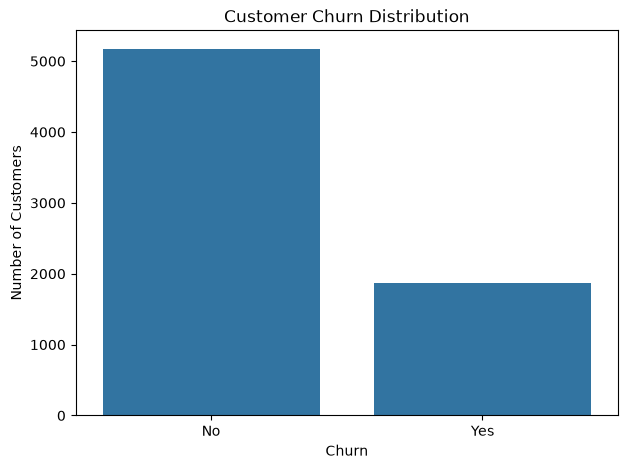

In [7]:
df["Churn"].value_counts()

churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

#plt.show()

churn_percentage = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_percentage

### Target Distribution Observation

The target variable is imbalanced:

- **26.54%** of customers churned.
- **73.46%** of customers did not churn.

Because of this imbalance, accuracy alone may not adequately represent model performance. Therefore, ROC-AUC, precision, recall, and F1-score are considered during model evaluation.

### Data Cleaning

`TotalCharges` is originally stored as text. Blank values are converted to missing values and then handled before modeling.

The cleaning is performed directly on the main dataframe `df` so that the rest of the notebook uses one consistent dataset.

In [21]:
# Clean TotalCharges directly in df

df["TotalCharges"] = df["TotalCharges"].astype(str).str.strip()

# Convert to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("TotalCharges dtype:", df["TotalCharges"].dtype)

Missing TotalCharges: 0
TotalCharges dtype: float64


## 3. Exploratory Data Analysis

The EDA focuses on relationships between customer characteristics and churn. The analysis is descriptive: observed differences do not by themselves establish causal relationships.

## 3. Exploratory Data Analysis

The exploratory analysis is performed to understand customer
characteristics, service usage, account information, and their
relationship with customer churn.

The analysis focuses on identifying patterns that may help explain
why customers leave ConnectTel and which variables may be useful
for predictive modeling.

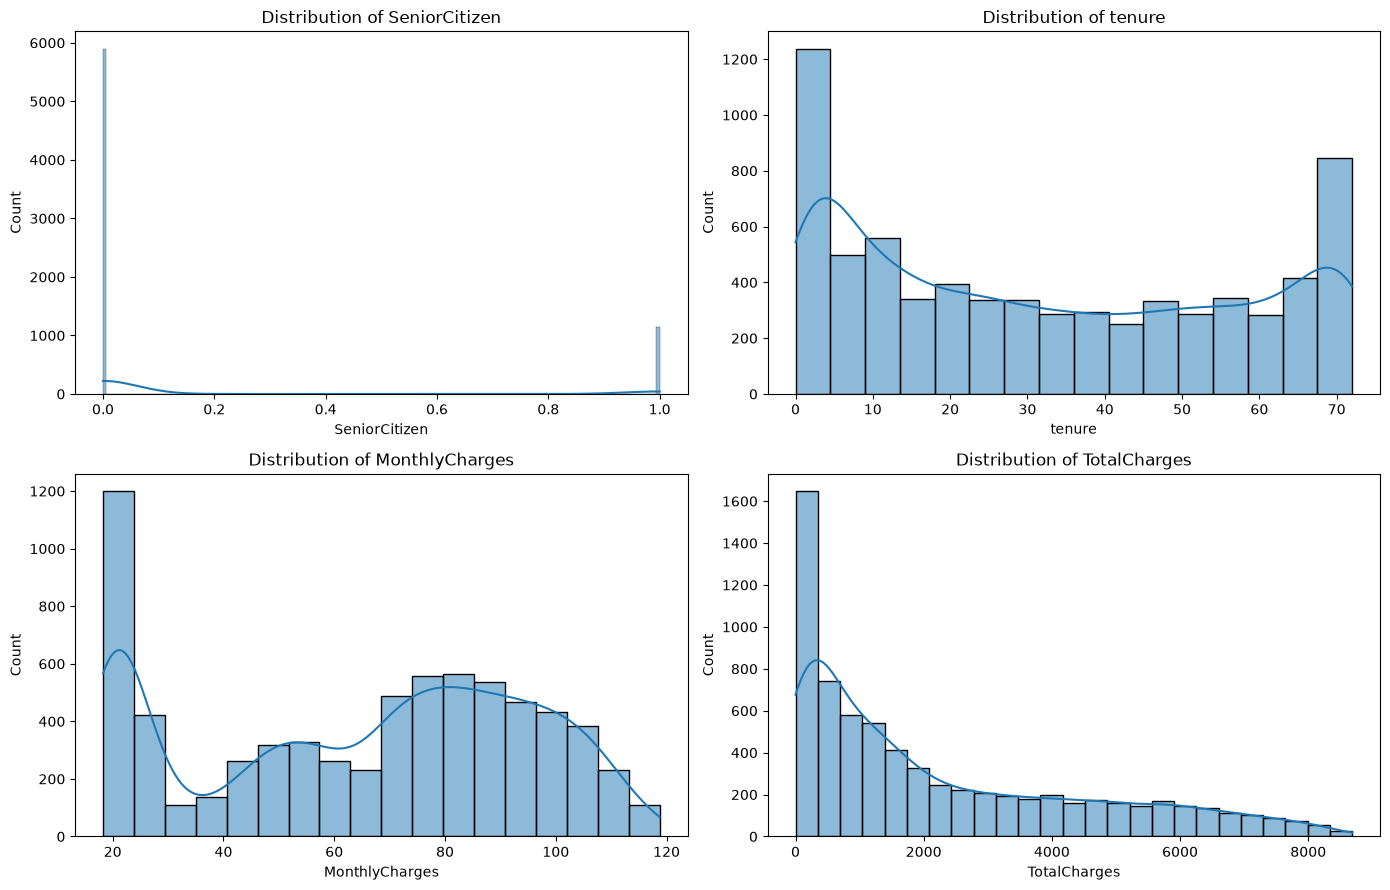

In [23]:
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numeric_cols].describe().T

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

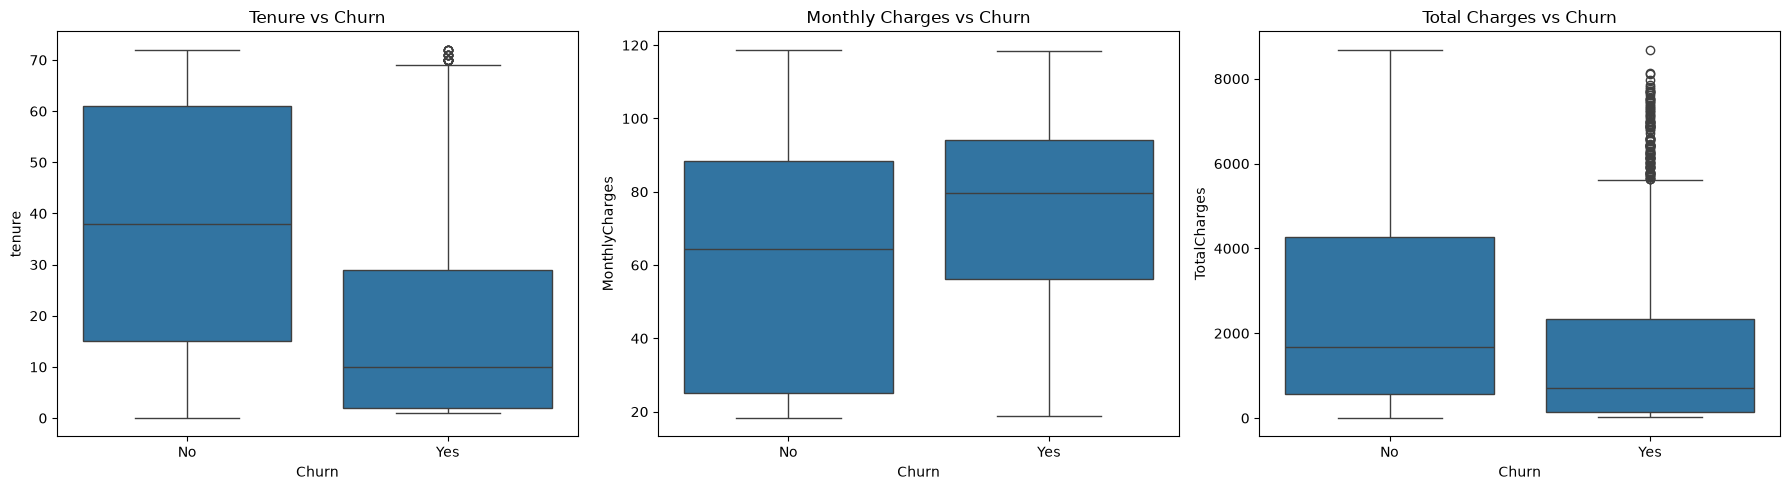

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure vs Churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges vs Churn")

sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[2])
axes[2].set_title("Total Charges vs Churn")

plt.tight_layout()
plt.show()

**Figure 1. Numerical feature distributions.**  
The distributions provide a first look at tenure, monthly charges, total charges, and other numerical characteristics before modeling.

In [37]:
def churn_rate_by(column):
    result = (
        pd.crosstab(
            df[column],
            df["Churn"],
            normalize="index"
        ) * 100
    )
    
    return result.round(2)

churn_rate_by("InternetService")



Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


### Hypothesis: Does having a partner reduce churn?

The analysis shows a clear difference in observed churn rates between
customers with and without a partner.

Customers without a partner have a churn rate of 32.96%, compared with
19.66% for customers who have a partner. This represents a difference
of 13.30 percentage points.

Therefore, in this dataset, customers without a partner show a higher
observed churn rate than customers with a partner.

This relationship is observational and does not by itself establish
that having a partner directly causes lower churn.

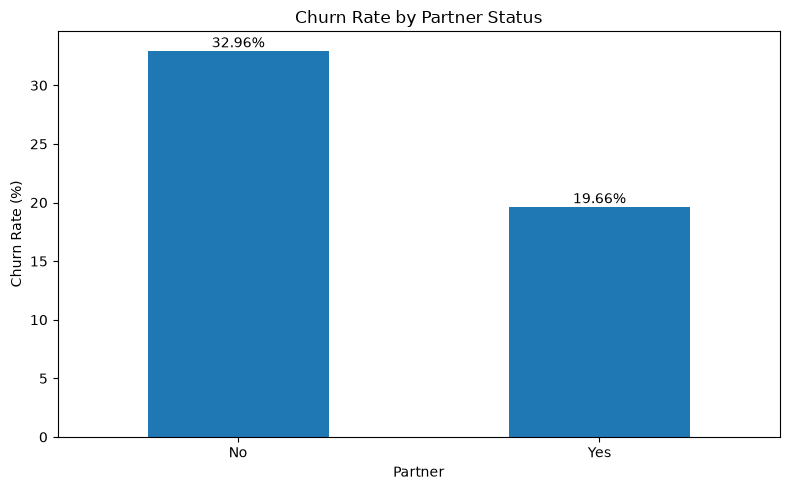

In [35]:
partner_churn = churn_rate_by("Partner")

ax = partner_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%"
    )

plt.tight_layout()
plt.show()


**Figure 2. Churn rate by partner status.**  
Customers without a partner have an observed churn rate of **32.96%**, compared with **19.66%** for customers with a partner, a difference of **13.30 percentage points**. This is an association in the dataset, not a causal conclusion.

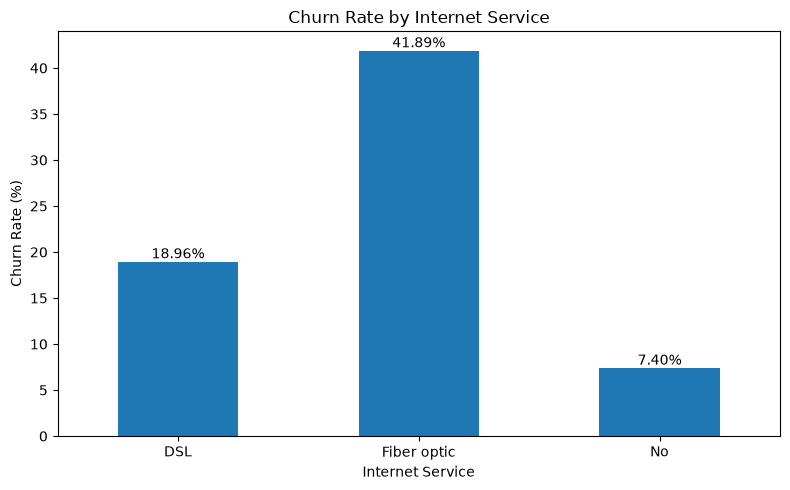

In [38]:
internet_churn = churn_rate_by("InternetService")

ax = internet_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%"
    )

plt.tight_layout()
plt.show()

**Figure 3. Churn rate by internet service.**  
Fiber optic customers have an observed churn rate of **41.89%**, compared with **18.96%** for DSL customers. The difference identifies fiber optic customers as a segment for further investigation.

In [39]:
churn_rate_by("Contract")

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


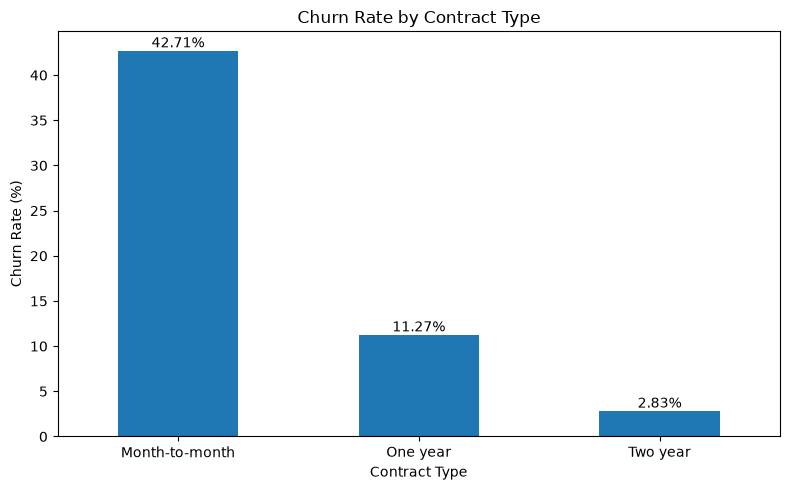

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [41]:
contract_churn = churn_rate_by("Contract")

ax = contract_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()
contract_counts = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

display(contract_counts)

**Figure 4. Churn rate by contract type.**  
Month-to-month customers have an observed churn rate of **42.71%**, compared with **11.27%** for one-year contracts and **2.83%** for two-year contracts.

In [42]:
churn_rate_by("PaymentMethod")

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


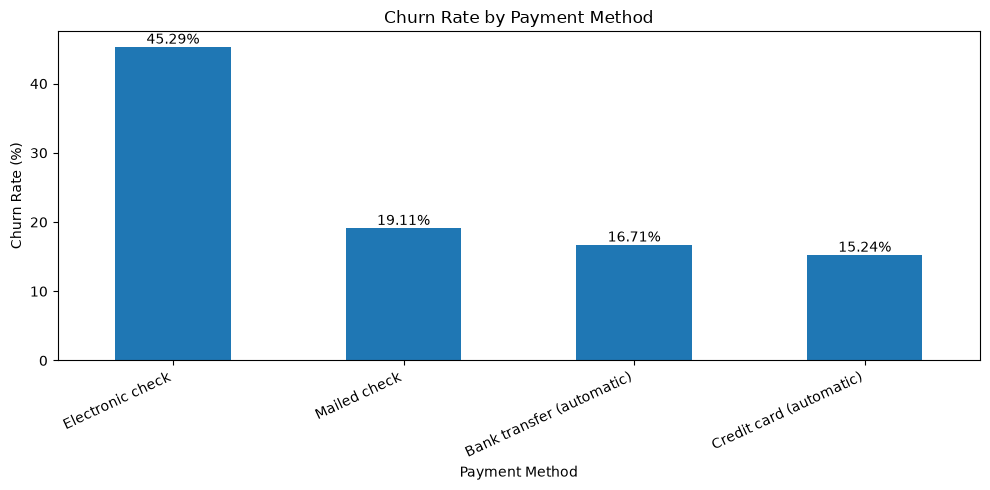

In [43]:
payment_churn = churn_rate_by("PaymentMethod")

ax = payment_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()

**Figure 5. Churn rate by payment method.**  
Payment method shows different observed churn rates across customer groups and is therefore included as a categorical modeling feature.

In [44]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for col in service_columns:
    print(f"\n{'=' * 60}")
    print(f"{col}")
    display(churn_rate_by(col))


PhoneService


Churn,No,Yes
PhoneService,,
No,75.07,24.93
Yes,73.29,26.71



MultipleLines


Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61



OnlineSecurity


...

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17



StreamingTV


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07



StreamingMovies


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


**Figure 6. Churn patterns across individual services.**  
Several services show substantial differences in observed churn rates. For example, customers without Online Security or Tech Support have higher observed churn rates than customers with those services.

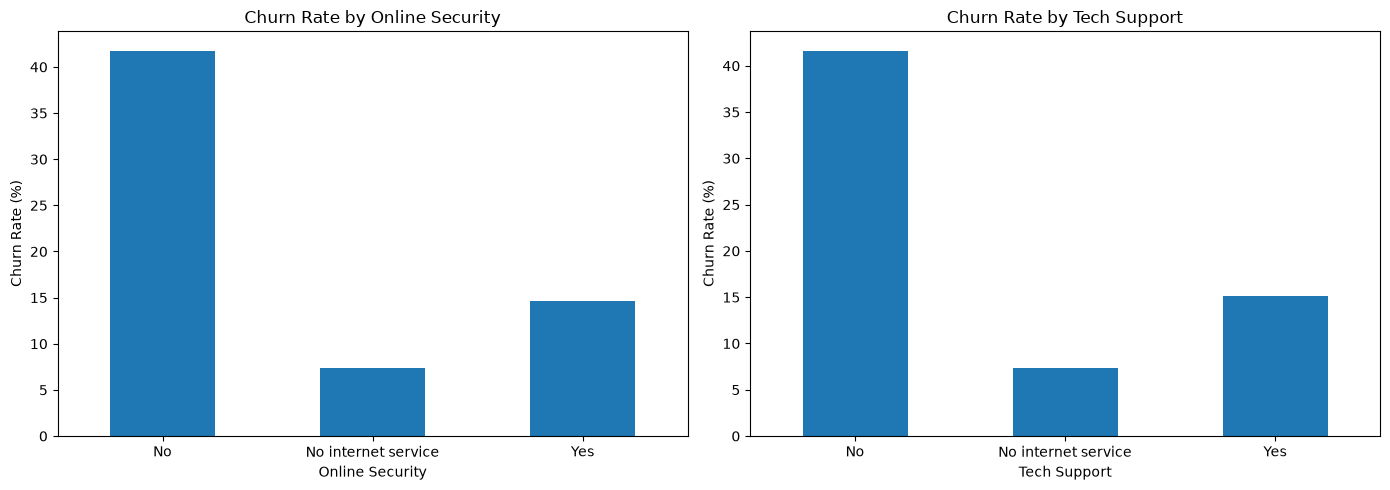

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

security_churn = churn_rate_by("OnlineSecurity")

security_churn["Yes"].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Churn Rate by Online Security")
axes[0].set_xlabel("Online Security")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].tick_params(axis="x", rotation=0)

support_churn = churn_rate_by("TechSupport")

support_churn["Yes"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Churn Rate by Tech Support")
axes[1].set_xlabel("Tech Support")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2)

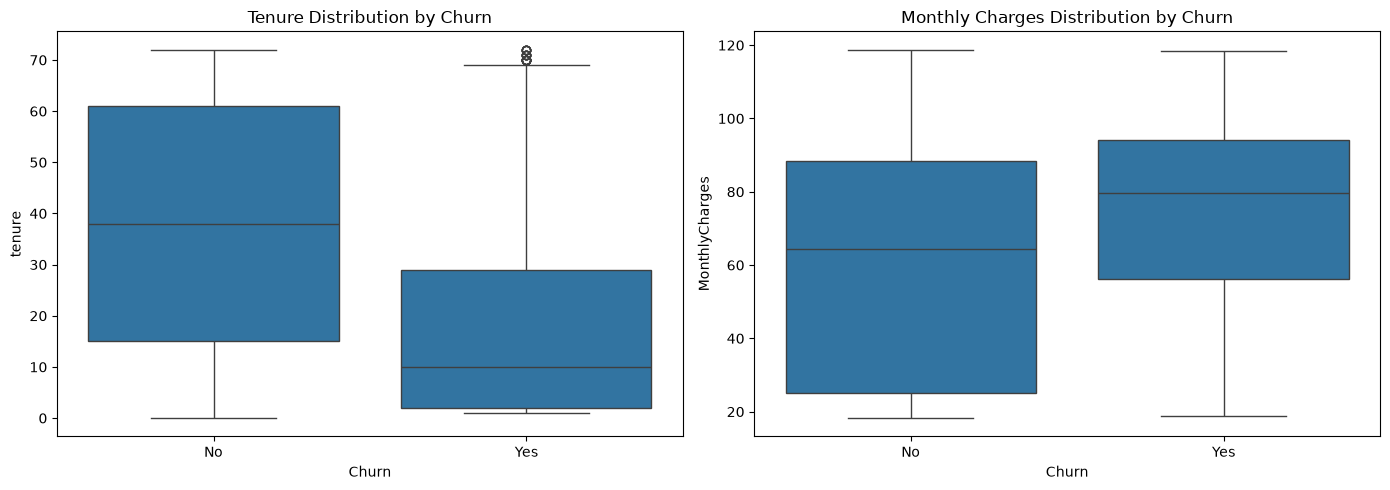

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    ax=axes[0]
)

axes[0].set_title("Tenure Distribution by Churn")

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    ax=axes[1]
)

axes[1].set_title("Monthly Charges Distribution by Churn")

plt.tight_layout()
plt.show()

## 4. Feature Engineering

Three additional features were created to provide the models with more useful representations of the original data:

1. `TotalChargesPerTenure`
2. `ServiceCount`
3. `TenureGroup`

`TenureGroup` is used for analysis/EDA, while the numeric features are used directly in the modeling pipeline.

In [51]:
# ==============================
# FEATURE ENGINEERING
# ==============================

# 1. Average charge per month of tenure
df["TotalChargesPerTenure"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    df["MonthlyCharges"]
)

# 2. Number of subscribed services
service_features = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["ServiceCount"] = df[service_features].apply(
    lambda row: sum(value == "Yes" for value in row),
    axis=1
)

# 3. Customer lifecycle group
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

print("Feature engineering completed.")
print("\nNew features:")
print([
    "TotalChargesPerTenure",
    "ServiceCount",
    "TenureGroup"
])

display(
    df[
        [
            "tenure",
            "TotalCharges",
            "TotalChargesPerTenure",
            "ServiceCount",
            "TenureGroup",
            "Churn"
        ]
    ].head()
)

Feature engineering completed.

New features:
['TotalChargesPerTenure', 'ServiceCount', 'TenureGroup']


,tenure,TotalCharges,TotalChargesPerTenure,ServiceCount,TenureGroup,Churn
0,1,29.85,29.850000,1,0-12 months,No
1,34,1889.50,55.573529,3,25-48 months,No
2,2,108.15,54.075000,3,0-12 months,Yes
3,45,1840.75,40.905556,3,25-48 months,No
4,2,151.65,75.825000,1,0-12 months,Yes


,TotalChargesPerTenure,ServiceCount,tenure
Churn,,,
No,61.27,3.45,37.57
Yes,74.43,3.13,17.98


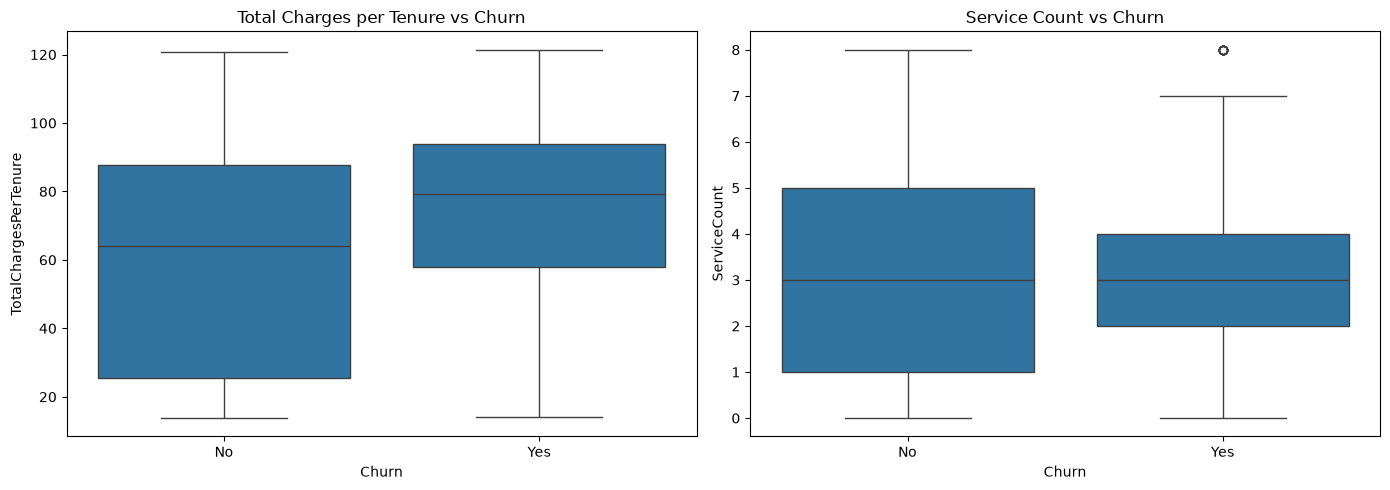

In [52]:
# Analyze engineered features against churn

display(
    df.groupby("Churn")[
        ["TotalChargesPerTenure", "ServiceCount", "tenure"]
    ].mean().round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalChargesPerTenure",
    ax=axes[0]
)
axes[0].set_title("Total Charges per Tenure vs Churn")

sns.boxplot(
    data=df,
    x="Churn",
    y="ServiceCount",
    ax=axes[1]
)
axes[1].set_title("Service Count vs Churn")

plt.tight_layout()
plt.show()

**Figure 7. Engineered feature analysis.**  
The engineered features are examined against churn to understand whether the additional representations provide useful patterns before model training.

## 5. Correlation Analysis

A correlation matrix is used to inspect relationships among numerical variables and the encoded churn target.

Correlation is used as an exploratory tool here and is not treated as proof of causation.

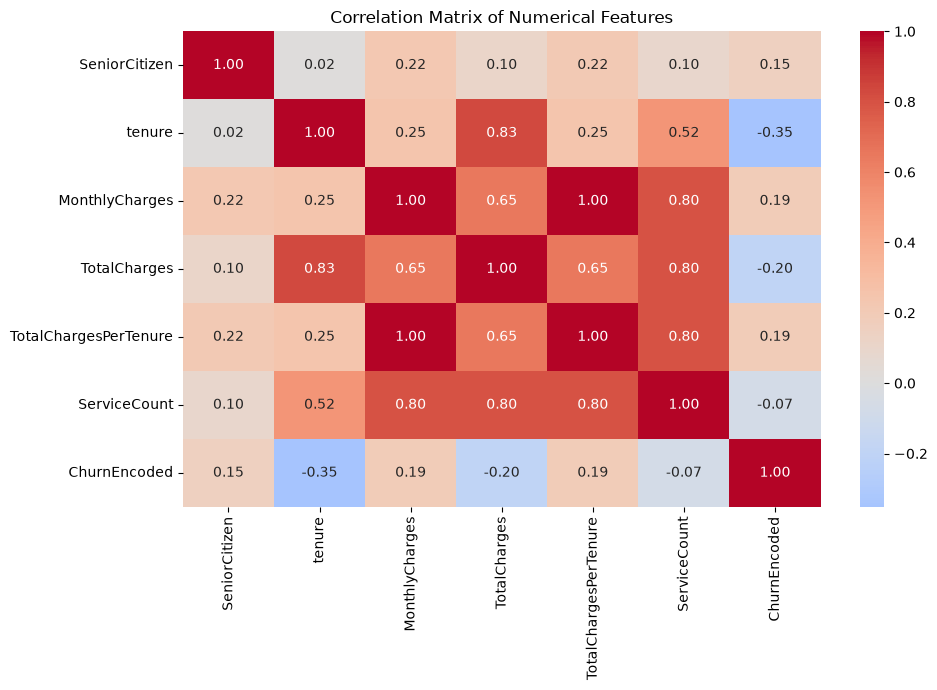

In [53]:
# Encode Churn temporarily for correlation analysis
corr_df = df.copy()

corr_df["ChurnEncoded"] = corr_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

correlation_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "TotalChargesPerTenure",
    "ServiceCount",
    "ChurnEncoded"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_df[correlation_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Figure 8. Correlation matrix.**  
The correlation matrix summarizes linear relationships among numerical features and the encoded churn target. Correlation does not imply causation.

## 6. Train/Test Split

The dataset is divided into training and test sets using an 80/20 stratified split.

Stratification keeps the churn proportion approximately consistent between the two sets and prevents information from the test set from being used during model fitting.

In [55]:
from sklearn.model_selection import train_test_split

# Remove identifier
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Test churn rate:", round(y_test.mean() * 100, 2), "%")

Training set: (5634, 22)
Test set: (1409, 22)
Training churn rate: 26.54 %
Test churn rate: 26.54 %


### Preprocessing

Numerical variables are standardized using `StandardScaler`.

Categorical variables are one-hot encoded using `OneHotEncoder` with `handle_unknown="ignore"` and `drop="first"`.

`TenureGroup` is retained as an engineered analytical feature but is not included in the current model matrix because the executed model results were produced without it. This keeps the notebook's code and reported model results consistent.

In [56]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = X.select_dtypes(
    include="str"
).columns.tolist()

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalChargesPerTenure', 'ServiceCount']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 7. Model Training

Three classification models are evaluated:

- **Logistic Regression** — baseline linear classifier
- **Random Forest** — tree-based ensemble model
- **XGBoost** — gradient boosting model

The models are placed inside preprocessing pipelines so that preprocessing is fitted only on the training data within each validation split.

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

# Models
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [61]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", logistic_model)
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", random_forest_model)
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])

## 8. Cross-Validation

Stratified 5-fold cross-validation is used on the training set.

The primary validation metric is **ROC-AUC**, while precision and recall are also considered during final evaluation because the target classes are imbalanced.

In [62]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV AUC": scores.mean(),
        "Std CV AUC": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        "Mean CV AUC",
        ascending=False
    )
)

,Model,Mean CV AUC,Std CV AUC
0,Logistic Regression,0.845645,0.012423
2,XGBoost,0.844125,0.010295
1,Random Forest,0.828971,0.008615


## 9. Hyperparameter Tuning

`GridSearchCV` is used to search over model hyperparameters using stratified 5-fold cross-validation.

The optimization objective is ROC-AUC.

In [63]:
logistic_params = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["liblinear", "lbfgs"]
}

logistic_grid = GridSearchCV(
    logistic_pipeline,
    logistic_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)
print("Best CV AUC:", logistic_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Logistic Regression parameters:
{'model__C': 10, 'model__solver': 'liblinear'}
Best CV AUC: 0.8457976594196743


In [64]:
rf_params = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)
print("Best CV AUC:", rf_grid.best_score_)


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV AUC: 0.8441152629110217


In [65]:
xgb_params = {
    "model__n_estimators": [200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [3, 4, 5],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    xgb_pipeline,
    xgb_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

print("Best XGBoost parameters:")
print(xgb_grid.best_params_)
print("Best CV AUC:", xgb_grid.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best XGBoost parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best CV AUC: 0.8502762143959058


## 10. Final Model Evaluation

The tuned models are evaluated on the held-out test set.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix
- ROC Curve

In [67]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

final_models = {
    "Logistic Regression": logistic_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "XGBoost": xgb_grid.best_estimator_
}

evaluation_results = []

for name, model in final_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_prob)
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.sort_values(
        "AUC-ROC",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1,AUC-ROC
2,XGBoost,0.7999,0.6597,0.5080,0.5740,0.8472
1,Random Forest,0.7551,0.5266,0.7674,0.6246,0.8414
0,Logistic Regression,0.8041,0.6531,0.5588,0.6023,0.8413


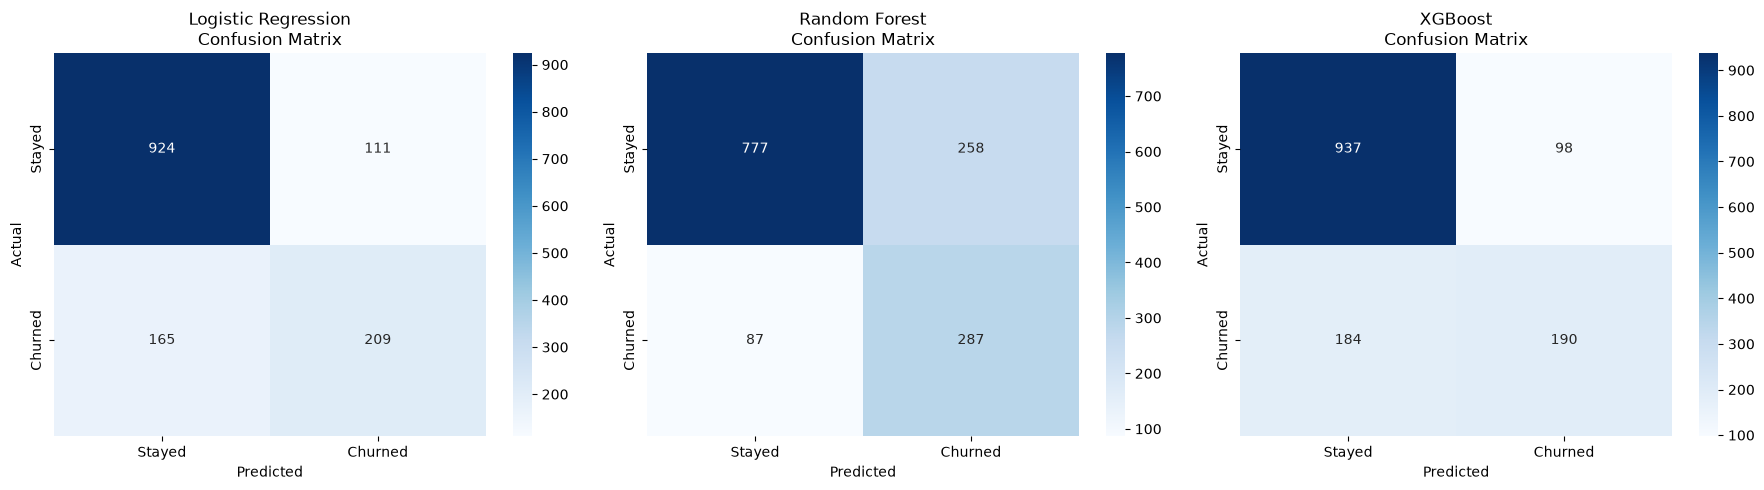

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, (name, model) in zip(axes, final_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Stayed", "Churned"],
        yticklabels=["Stayed", "Churned"]
    )

    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

**Figure 9. Confusion matrices for the final models.**  
The confusion matrices show correct predictions as well as false positives and false negatives for each model.

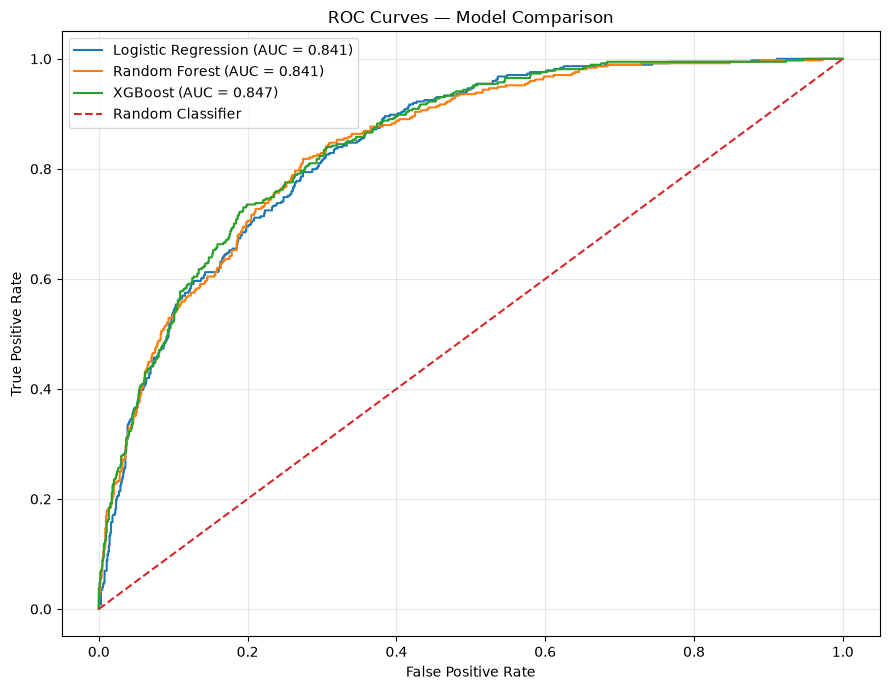

In [69]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 7))

for name, model in final_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Figure 10. ROC curves for the final models.**  
The ROC curves compare model discrimination across classification thresholds. The AUC values are reported directly in the legend.

### Model Comparison

The table below compares the final tuned models on the unseen test set.

The results should be interpreted together rather than relying on accuracy alone. In particular, recall indicates how many actual churners were identified, while ROC-AUC measures ranking/discrimination performance across thresholds.

In [70]:
final_comparison = evaluation_df.copy()

final_comparison = final_comparison.sort_values(
    "AUC-ROC",
    ascending=False
).reset_index(drop=True)

display(
    final_comparison.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "AUC-ROC": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1,AUC-ROC
0,XGBoost,0.800,0.660,0.508,0.574,0.847
1,Random Forest,0.755,0.527,0.767,0.625,0.841
2,Logistic Regression,0.804,0.653,0.559,0.602,0.841


### Test-set interpretation

On the held-out test set:

- **XGBoost:** AUC-ROC = **0.8472**, accuracy = 0.7999, precision = 0.6597, recall = 0.5080, F1 = 0.5740.
- **Random Forest:** AUC-ROC = **0.8414**, with the highest recall among the three models at **0.7674**.
- **Logistic Regression:** AUC-ROC = **0.8413**, with accuracy = 0.8041.

The XGBoost model has the highest test ROC-AUC in this experiment, so it is selected for the SHAP interpretation step. Random Forest identifies a larger proportion of actual churners at the default classification threshold, illustrating the practical trade-off between discrimination and recall.

## 11. SHAP Model Interpretation

SHAP is used to explain the selected model and identify which transformed features contribute most to its predictions.

The selected model is the model with the highest held-out test ROC-AUC in the comparison above.

In [71]:
best_model_name = final_comparison.iloc[0]["Model"]
best_model = final_models[best_model_name]

print("Model selected for SHAP analysis:", best_model_name)

Model selected for SHAP analysis: XGBoost


In [72]:
preprocessor_fitted = best_model.named_steps["preprocessor"]
model_fitted = best_model.named_steps["model"]

feature_names = preprocessor_fitted.get_feature_names_out()

X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(X_test)

print("Number of model features:", len(feature_names))

Number of model features: 32


c:\Users\Shahid\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


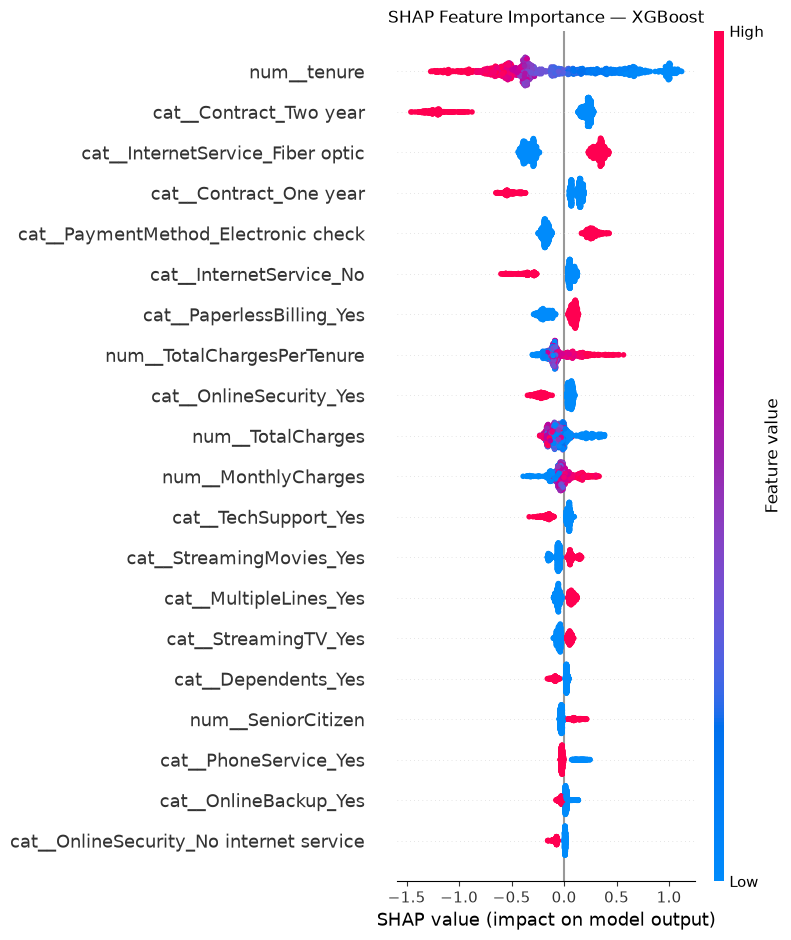

In [75]:
import shap

if best_model_name in ["XGBoost", "Random Forest"]:

    explainer = shap.TreeExplainer(model_fitted)

    shap_values = explainer.shap_values(
        X_test_transformed
    )

    # Handle different SHAP output formats
    if isinstance(shap_values, list):
        shap_values_plot = shap_values[1]
    else:
        shap_values_plot = shap_values

    shap.summary_plot(
        shap_values_plot,
        X_test_transformed,
        feature_names=feature_names,
        show=False
    )

    plt.title(f"SHAP Feature Importance — {best_model_name}")
    plt.tight_layout()
    plt.show()

**Figure 11. SHAP summary plot.**  
The SHAP summary plot shows how transformed features contribute to individual model predictions and highlights the features with the largest overall contribution.

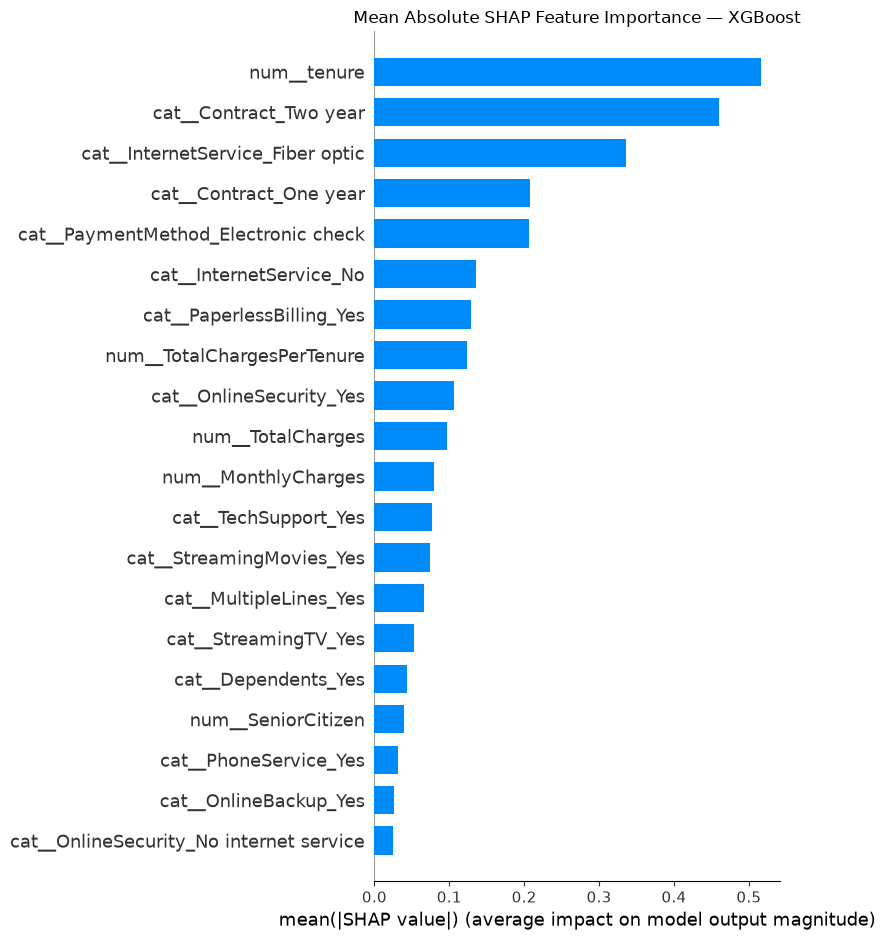

In [76]:
if best_model_name in ["XGBoost", "Random Forest"]:

    shap.summary_plot(
        shap_values_plot,
        X_test_transformed,
        feature_names=feature_names,
        plot_type="bar",
        show=False
    )

    plt.title(
        f"Mean Absolute SHAP Feature Importance — {best_model_name}"
    )

    plt.tight_layout()
    plt.show()

**Figure 12. Mean absolute SHAP feature importance.**  
This bar plot summarizes the average magnitude of each feature's contribution to the selected model's predictions.

In [77]:
import joblib

joblib.dump(
    best_model,
    "../outputs/models/connecttel_churn_model.pkl"
)

print("Best model saved successfully.")

Best model saved successfully.


# 12. Business Insight Report

## Key Findings

### 1. Contract Type

Month-to-month customers have a **42.71%** observed churn rate, compared with **11.27%** for one-year contracts and **2.83%** for two-year contracts.

**Business implication:** Month-to-month customers represent an important segment for targeted retention activity.

### 2. Internet Service

Fiber optic customers have a **41.89%** observed churn rate, compared with **18.96%** for DSL customers.

**Business implication:** The fiber optic segment should be investigated further for pricing, service quality, support, and competitive factors.

### 3. Tenure

Customers who churn have substantially shorter tenure than customers who stay. The mean tenure is approximately **18 months** for churned customers versus **38 months** for retained customers.

**Business implication:** The early customer lifecycle is an important period for engagement and retention.

### 4. Monthly Charges

Churned customers have higher average monthly charges than retained customers.

**Business implication:** High-charge customers with elevated predicted churn risk can be reviewed for suitable plan or loyalty options.

### 5. Service Features

Customers without services such as Online Security and Tech Support show higher observed churn rates in this dataset.

**Business implication:** ConnectTel can test whether relevant service bundles, onboarding, or support offers improve retention.

## Actionable Recommendations

### Recommendation 1 — Contract Retention

Identify high-risk month-to-month customers and test targeted incentives for moving to longer-term contracts.

Possible actions:

- Contract discounts
- Loyalty benefits
- Bundled services
- Limited-time upgrade offers

### Recommendation 2 — Early-Tenure Engagement

Create an early-stage retention program for newer customers.

Possible actions:

- Welcome and onboarding campaigns
- Service setup assistance
- Early satisfaction checks
- Proactive support follow-ups

### Recommendation 3 — High Monthly Charge Review

For customers with high predicted churn probability and high monthly charges, review whether their current plan provides sufficient value.

Possible actions:

- Personalized plans
- Bundle discounts
- Service optimization
- Loyalty offers

### Recommendation 4 — Fiber Optic Investigation

The higher observed churn rate among fiber optic customers should trigger further business investigation rather than an assumption that fiber service causes churn.

ConnectTel should examine:

- Pricing
- Service quality
- Technical issues
- Customer support
- Competitor offers
- Customer satisfaction

### Recommendation 5 — Service-Based Retention

Where appropriate, customers without Online Security or Tech Support can be offered relevant service bundles or support options.

The effectiveness of these interventions should be measured through controlled retention campaigns.

## Recommended Retention Workflow

```text
Customer Data
      ↓
Churn Prediction Model
      ↓
Predicted Churn Probability
      ↓
Identify High-Risk Customers
      ↓
Combine Risk With Customer Value
      ↓
Choose Appropriate Retention Action
      ↓
Measure Customer Response
```

The model should be treated as a **decision-support tool**, not as proof that a customer will churn.



# 13. Final Conclusion

This project developed an end-to-end machine learning workflow for predicting customer churn at ConnectTel.

The analysis identified clear differences in observed churn across contract type, internet service, tenure, monthly charges, and several subscribed services.

Three classification models were trained and tuned using stratified 5-fold cross-validation with ROC-AUC as the main optimization metric. The final models were evaluated on a held-out test set using accuracy, precision, recall, F1-score, and ROC-AUC.

In the final test evaluation, XGBoost achieved the highest ROC-AUC (**0.8472**) and was therefore selected for SHAP interpretation. The model's predictions were further analyzed using SHAP to improve interpretability.

The main business outcome of the project is a workflow that connects:

**Customer Data → Churn Prediction → Risk Identification → Model Interpretation → Targeted Retention Actions**

The recommendations should be validated with real customer behavior and controlled business experiments before being deployed as operational retention policies.